In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

adata = adata_HD
# -----------------------------
# Configuration parameters (modify as needed)
# -----------------------------
celltypes_groupA = ["B cell"]
celltype_groupB = ["T cell"]
gene1 = None 
gene2 = None 
group_key = "batch"          # Column name used for grouping
radii_um = np.arange(5, 101, 5)  # The unit is micrometers

# -----------------------------
# Data preprocessing
# -----------------------------
X_dense = adata.X.toarray() if hasattr(adata.X, "toarray") else np.array(adata.X)
idx_gene1 = None if gene1 is None else adata.var_names.get_loc(gene1)
idx_gene2 = None if gene2 is None else adata.var_names.get_loc(gene2)

# -----------------------------
# Custom colocalization score function
# -----------------------------
def compute_coloc_score(coords, mask_A, mask_B, radius_px, adata):
    """
    Calculate P(A | within radius of B) / P(A)
    Note: radius_px here must be the distance in pixel units
    """
    if mask_A.sum() == 0 or mask_B.sum() == 0:
        return np.nan

    coords_B = coords[mask_B]
    dist_to_B = cdist(coords, coords_B)  # (n_spots, n_B), unit is pixels
    in_neigh_of_B = (dist_to_B <= radius_px).any(axis=1)  # (n_spots,)

    if in_neigh_of_B.sum() == 0:
        return np.nan

    A_in_neigh = mask_A & in_neigh_of_B
    return A_in_neigh.sum() / in_neigh_of_B.sum()

# -----------------------------
# Calculate scores grouped by effect
# -----------------------------
effect_groups = adata.obs[group_key].dropna().unique()
all_scores = {}

for group in sorted(effect_groups):
    print(f"Processing group: {group}")
    
    group_mask = adata.obs[group_key] == group
    sub_adata = adata[group_mask].copy()
    sub_coords = sub_adata.obsm["spatial"]
    sub_X = X_dense[group_mask]

    # Dynamically obtain the conversion factor for the current sample
    try:
        microns_per_pixel = sub_adata.uns["spatial"][group]["sample"]["scalefactors"]["microns_per_pixel"]
    except KeyError:
        raise ValueError(f"Cannot find 'microns_per_pixel' in adata.uns['spatial']['{group}']['sample']['scalefactors']")

    # Convert physical micrometer radius to pixel radius
    radii_px = radii_um / microns_per_pixel

    mask_A = sub_adata.obs["type"].isin(celltypes_groupA) if gene1 is None else (
        sub_adata.obs["type"].isin(celltypes_groupA) &
        (sub_X[:, idx_gene1] > 0)
    )

    mask_B = sub_adata.obs["type"].isin(celltype_groupB) if gene2 is None else (
        sub_adata.obs["type"].isin(celltype_groupB) &
        (sub_X[:, idx_gene2] > 0)
    )

    print(f"A spots: {np.sum(mask_A)}, B spots: {np.sum(mask_B)}")
    
    #Pass the converted pixel radii
    scores = []
    for r_px in radii_px:
        s = compute_coloc_score(sub_coords, mask_A.values, mask_B.values, radius_px=r_px, adata=sub_adata)
        scores.append(s)
    all_scores[group] = scores

Processing group: nS01
A spots: 61, B spots: 84
Processing group: nS02
A spots: 38, B spots: 25
Processing group: nS03
A spots: 2630, B spots: 149
Processing group: nS06
A spots: 13685, B spots: 39112


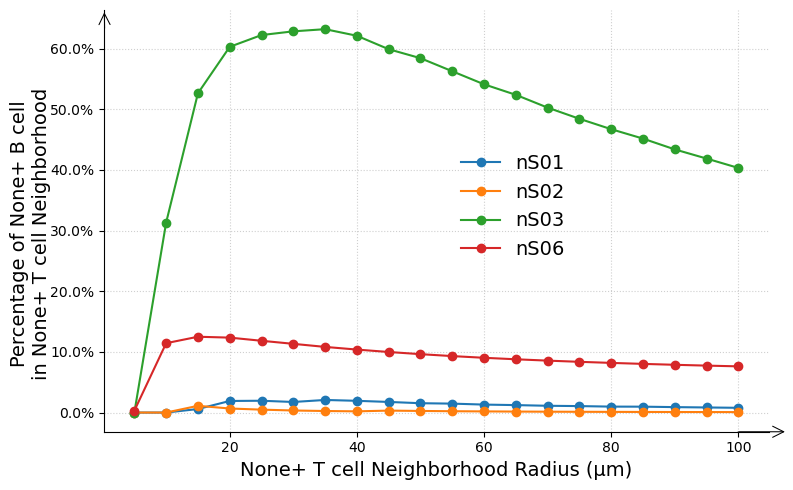

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(figsize=(8, 5)) 

for group, scores in all_scores.items():
    ax.plot(radii_um, scores, marker='o', label=f"{group}")  

ax.set_xlabel(f"{gene2}+ {celltype_groupB[0]} Neighborhood Radius (µm)",fontsize = 14)
ax.set_ylabel(f"Percentage of {gene1}+ {'/'.join(celltypes_groupA)}\nin {gene2}+ {celltype_groupB[0]} Neighborhood",fontsize=14)
ax.yaxis.set_label_coords(-0.08, 0.47) 

# Hide the top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(title="",bbox_to_anchor=(0.72,0.7), frameon=False,fontsize=14)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0, decimals=1))
ax.grid(True, linestyle=":", alpha=0.6)

# Add arrows to the x- and y-axes
def add_arrow(ax, axis):
    if axis == 'x':
        arrow_start_x = ax.get_xlim()[1] - 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])
        arrow_start_y = ax.get_ylim()[0] - 0.25/4000
        arrow_end_x = ax.get_xlim()[1] + 3
        arrow_end_y = arrow_start_y 
    elif axis == 'y':
        arrow_start_x = ax.get_xlim()[0] + 0.125 -0.05
        arrow_start_y = ax.get_ylim()[1]- 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])
        arrow_end_x = arrow_start_x -0.05
        arrow_end_y = ax.get_ylim()[1] + 3/4000

    arrow = FancyArrowPatch((arrow_start_x, arrow_start_y),
                            (arrow_end_x, arrow_end_y),
                            arrowstyle='->',
                            mutation_scale=20,
                           clip_on=False,
                           lw=0.75)
    ax.add_patch(arrow)

add_arrow(ax, 'x')
add_arrow(ax, 'y')

plt.tight_layout()
plt.show()

In [1]:
def cut_regions_from_adata(adata, regions_per_sample):
    """
    Extract cells within specified rectangular regions based on each sample's own coordinate system.

    The input (x, y, width, height) is relative to each sample's coordinate system,
    with coordinate fields assumed to be 'array_col' (x) and 'array_row' (y).

    Parameters:
    ----------
    adata : AnnData
        Contains obs['batch'], obs['array_row'], obs['array_col'],
        and uns['spatial'] dictionary (keyed by sample name).

    regions_per_sample : list of tuples
        [(sample_id, x, y, width, height), ...]
        - x, y: starting coordinates in the sample's coordinate system
          (typically corresponding to array_col, array_row)
        - width, height: width and height of the cropping region

    Returns:
    -------
    dict: {sample_id: cropped_adata}
    """

    x, y, w, h = regions_per_sample
    # Step 1: Extract all cells from this sample
    tp = adata

    # Step 3: Retrieve coordinates (x = array_col, y = array_row)
    x_coords = tp.obsm['spatial'][:, 0]
    y_coords = tp.obsm['spatial'][:, 1]

    # Step 4: Define the cropping range (closed interval)
    x_min, x_max = x, x + w
    y_min, y_max = y, y + h

    # Step 5: Filter cells within the region
    in_region = (
        (x_coords >= x_min) & (x_coords <= x_max) &
        (y_coords >= y_min) & (y_coords <= y_max)
    )

    if not in_region.any():
        print(f"Warning: No cells in region ({x}, {y}, {w}, {h})")

    # Step 6: Crop and save
    tp_cropped = tp[in_region].copy()

    return tp_cropped

In [2]:
import squidpy as sq
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def plot_HD(adata):
    # Treatment effect grouping
    treatment_effect = {
        "nS03": "good",
        "nS01": "poor",
        "nS02": "poor",
        "nS06": "good",
    }

    good_samples = [sample for sample, effect in treatment_effect.items() if effect == "good"]
    poor_samples = [sample for sample, effect in treatment_effect.items() if effect == "poor"]

    # Create a horizontal layout
    total_samples = len(good_samples) + len(poor_samples)
    fig, axes = plt.subplots(1, total_samples, figsize=(4 * total_samples, 6))

    gene1, gene2 =  None, None
    celltypes_groupA =  ["B cell"]
    celltype_groupB = ["T cell"]

    # Plot all samples
    for i, sample in enumerate(good_samples + poor_samples):
        tp = adata[adata.obs["batch"].isin([sample])].copy()
        tp.uns["spatial"] = {sample: tp.uns["spatial"][sample]}

        # Core fix: dynamically get the conversion factor for the current sample
        microns_per_pixel = tp.uns["spatial"][sample]["sample"]["scalefactors"]["microns_per_pixel"]

        # Set title color by treatment response
        effect = treatment_effect[sample]
        title_color = "#3B8B4F" if effect == "good" else "#C73E1D"

        # Build mask_A
        if gene1 is None:
            mask_A = tp.obs["type"].isin(celltypes_groupA).values
        else:
            genes1 = [gene1] if isinstance(gene1, str) else gene1
            idx_genes1 = [adata.var_names.get_loc(g) for g in genes1]
            mask_A = np.logical_and.reduce(
                [
                    tp.obs["type"].isin(celltypes_groupA).values,
                    *[np.asarray((tp.X[:, idx] > 0).todense()).flatten() for idx in idx_genes1],
                ]
            )

        # Build mask_B
        if gene2 is None:
            mask_B = tp.obs["type"].isin(celltype_groupB).values
        else:
            genes2 = [gene2] if isinstance(gene2, str) else gene2
            idx_genes2 = [adata.var_names.get_loc(g) for g in genes2]
            mask_B = np.logical_and.reduce(
                [
                    tp.obs["type"].isin(celltype_groupB).values,
                    *[np.asarray((tp.X[:, idx] > 0).todense()).flatten() for idx in idx_genes2],
                ]
            )

        from scipy.spatial import cKDTree

        # Get spatial coordinates and spot names for A and B
        coords_A = tp[mask_A].obsm["spatial"]
        coords_B = tp[mask_B].obsm["spatial"]
        names_B = tp[mask_B].obs_names.values

        # Build KD tree for B
        tree_B = cKDTree(coords_B)

        # Query nearest neighbor in B for each point in A
        distances, indices = tree_B.query(coords_A)

        try:
            # Find the index in A corresponding to the global minimum distance
            min_idx_in_A = np.argmin(distances)
            # Corresponding index and spot name in B
            closest_B_index = indices[min_idx_in_A]
            closest_B_name = names_B[closest_B_index]
        except Exception:
            print(f"No qualifying cells found in sample {sample}, skipping plot.")
            # Write a hint on the corresponding subplot
            axes[i].text(0.5, 0.5, "Not Found", fontsize=20, ha="center", va="center", color="gray")
            axes[i].set_title(sample, color=title_color, fontweight="bold", fontsize=18)
            axes[i].set_xticks([])
            axes[i].set_yticks([])
            for spine in axes[i].spines.values():
                spine.set_visible(False)
            # Skip the remaining plotting logic for this sample and proceed to the next
            continue


        # Create a temporary column for color encoding
        tp.obs["temp_color"] = np.where(
            np.asarray(mask_A).flatten(), "A", np.where(np.asarray(mask_B).flatten(), "B", "default")
        )

        # Set category and colors
        tp.obs["temp_color"] = pd.Categorical(tp.obs["temp_color"], categories=["A", "B", "default"])
        tp.uns["temp_color_colors"] = ["#F18F01", "#2E86AB", "lightgray"]

        idx_orig = tp.obs_names.get_loc(closest_B_name)
        orig_point_x, orig_point_y = tp.obsm["spatial"][idx_orig]

        # Core fix: convert physical distances 120 um and 130 um to correct pixel values
        crop_offset_px = 80 / microns_per_pixel
        plot_limit_px = 90 / microns_per_pixel

        # Use your original API call logic
        ax = sq.pl.spatial_scatter(
            cut_regions_from_adata(
                tp,
                (orig_point_x - crop_offset_px, orig_point_y - crop_offset_px, 2 * crop_offset_px, 2 * crop_offset_px),
            ),
            color="temp_color",
            shape=None,
            size=500.0,
            title=sample,
            legend_loc=None,
            ax=axes[i],
            return_ax=True,
            alpha=0.8,
        )

        ax.set_xlim(orig_point_x - plot_limit_px, orig_point_x + plot_limit_px)
        ax.set_ylim(orig_point_y - plot_limit_px, orig_point_y + plot_limit_px)

        # Draw concentric circles
        import matplotlib.patches as patches

        center = (orig_point_x, orig_point_y)
        radii_um = np.arange(20, 80 + 1, 20)
        theta1, theta2 = -5, 355

        for r_um in radii_um:
            # Core fix: convert physical radius to pixel radius for plotting
            r_px = r_um / microns_per_pixel

            arc = patches.Arc(center, 2 * r_px, 2 * r_px, color="gray", linestyle="--", linewidth=0.7, alpha=0.6)
            ax.add_patch(arc)

            # Label position also uses pixel offset, but text shows the real micron value
            ax.text(
                center[0],
                center[1] - r_px - (4 / microns_per_pixel),
                f"{r_um} µm",
                fontsize=16,
                ha="center",
                va="bottom",
                color="black",
                alpha=1.0,
            )
        # End of added section

        # Ensure the legend is removed
        if ax.get_legend() is not None:
            ax.get_legend().remove()

        # Set title color
        ax.set_title(sample, color=title_color, fontweight="bold", fontsize=20)

        # Remove axes and borders
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")
        for spine in ax.spines.values():
            spine.set_visible(False)

    # Add a divider between Good and Poor groups
    if len(good_samples) > 0 and len(poor_samples) > 0:
        divider_idx = len(good_samples)
        bbox = axes[divider_idx - 1].get_position()
        x_pos = bbox.x1

        fig.add_artist(
            plt.Line2D(
                [x_pos, x_pos], [0.22, 0.90], transform=fig.transFigure, color="black", linewidth=1.5, linestyle="--"
            )
        )

    # Manually create legend handles and labels
    legend_handles = []
    legend_labels = ["T Cells", "B Cells", "Others"]
    global_colors = ["#2E86AB", "#F18F01", "lightgray"]
    for i, (ct, color) in enumerate(zip(legend_labels, global_colors)):
        handle = plt.Line2D(
            [0], [0], marker="o", color="w", markerfacecolor=color, markersize=16, linestyle="None"
        )
        legend_handles.append(handle)

    # Add a unified legend
    fig.legend(
        legend_handles,
        legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.24),
        ncol=min(6, len(legend_labels)),
        fontsize=18,
        frameon=False,
        title="Cell Types",
        title_fontsize=18,
    )

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15)
    plt.show()

/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, 

In [3]:
import scanpy as sc
adata_HD = sc.read("./h5ad/adata_HD.h5ad")

/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


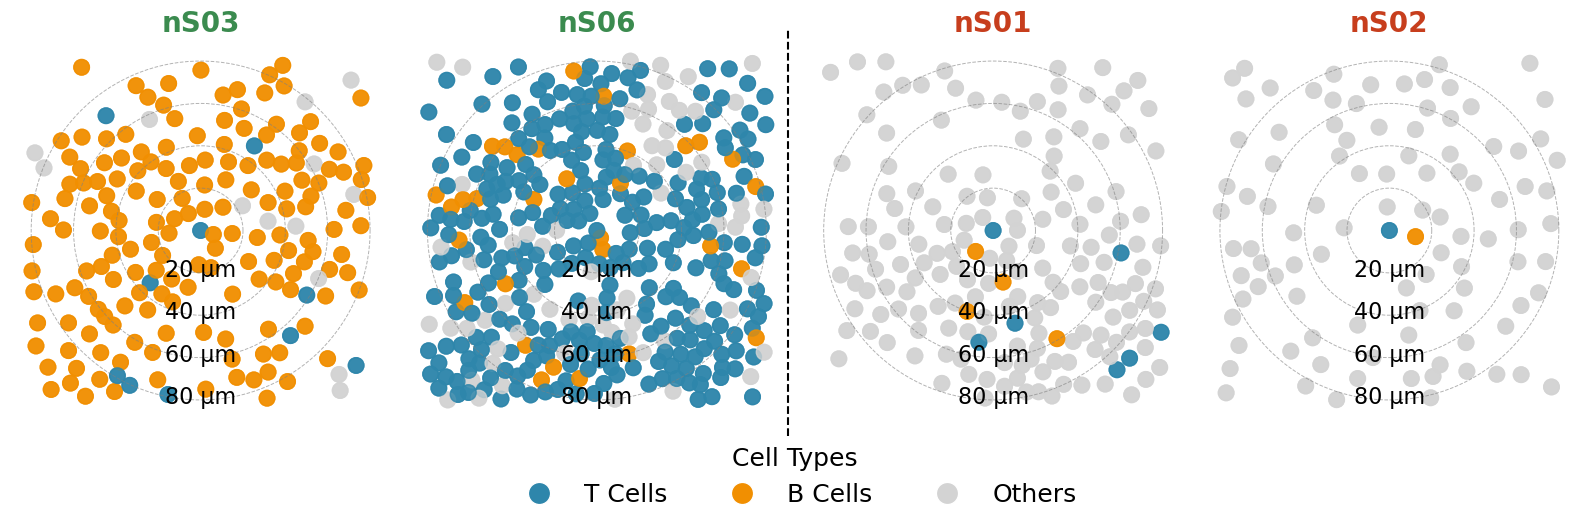

In [4]:
plot_HD(adata_HD)